## **Context**
Banknotes are one of the most important assets of a country. Some miscreants introduce fake notes which bear a resemblance to original note to create discrepancies of the money in the financial market. It is difficult for humans to tell true and fake banknotes apart especially because they have a lot of similar features.

**Motivation** Despite a decrease in the use of currency due to the recent growth in the use of electronic transactions, cash transactions remain very important in the global market. Banknotes are used to carry out financial activities. To continue with smooth cash transactions, entry of forged banknotes in circulation should be preserved. There has been a drastic increase in the rate of fake notes in the market. Fake money is an imitation of the genuine notes and is created illegally for various motives. These fake notes are created in all denominations which brings the financial market of the country to a low level. The various advancements in the field of scanners and copy machines have led the miscreants to create copies of banknotes. It is difficult for human-eye to recognize a fake note because they are created with great accuracy to look alike a genuine note. Security aspects of banknotes have to be considered and security features are to be introduced to mitigate fake currency. Hence, there is a dire need in banks and ATM machines to implement a system that classifies a note as genuine or fake.

[**Source of Information:** A research paper on Analysis of Banknote Authentication System using Machine Learning Techniques by Sumeet Shahani, Aisa Jagiasi and Priya RL at International Journal of Computer Applications (0975 – 8887) Volume 179 – No.20, February 2018]

**Objective**
Being a Data Science Enthusiast, you committed yourself to use the power of Data Science and come up with an efficient model that accurately predicts if a note is genuine or not.



## Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

### Loading Data

In [2]:
data = pd.read_csv("https://raw.githubusercontent.com/dphi-official/Datasets/master/bank_note_data/training_set_label.csv")
data.head()

,VWTI,SWTI,CWTI,EI,Class
0,2.2634,-4.4862,3.6558,-0.612510,0
1,3.2718,1.7837,2.1161,0.613340,0
2,-3.9411,-12.8792,13.0597,-3.312500,1
3,0.5195,-3.2633,3.0895,-0.984900,0
4,2.5698,-4.4076,5.9856,0.078002,0


Data Description

**VWTI**: Variance of Wavelet Transformed Image

**SWTI**: Skewness of Wavelet Transformed Image

**CWTI**: Curtosis of Wavelet Transformed Image

**EI**: Entropy of Image

**Class**: Class (1: genuine, 0: forged)

In [3]:
data.isnull().sum()

,0
VWTI,0
SWTI,0
CWTI,0
EI,0
Class,0


We have no missing values in our dataset

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   VWTI    1096 non-null   float64
 1   SWTI    1096 non-null   float64
 2   CWTI    1096 non-null   float64
 3   EI      1096 non-null   float64
 4   Class   1096 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 42.9 KB


<Axes: xlabel='Class'>

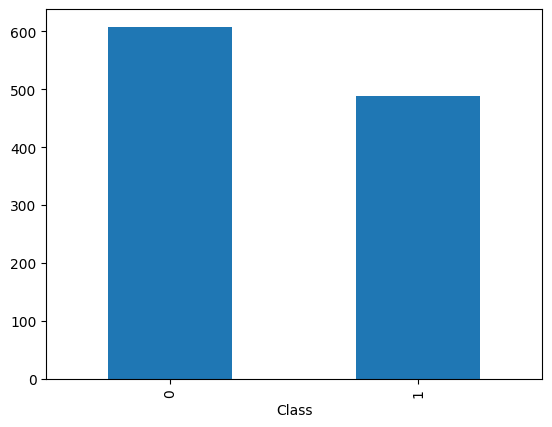

In [7]:
data['Class'].value_counts().plot(kind='bar',fill = "Class")

From the bargraph we can see that the distribution of bank notes for both original and forged is almost identical,

In [9]:
X = data.drop('Class', axis=1)
y = data['Class']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y ,test_size=0.2, random_state=42)

In [10]:
print(X_train.shape)
print(X_test.shape)

(876, 4)
(220, 4)


## BUilding an Artificial Neural Network

In [32]:
 model_1 = tf.keras.Sequential([
    tf.keras.layers.Dense(1,activation = "sigmoid",input_shape=(4,))
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model_1.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 1)                   │               5 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5 (20.00 B)

 Trainable params: 5 (20.00 B)

 Non-trainable params: 0 (0.00 B)

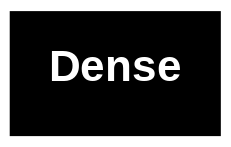

In [29]:
tf.keras.utils.plot_model(model_1)

### Compiling our model

In [37]:
model_1.compile(optimizer = "adam",loss="binary_crossentropy",metrics = ["accuracy"])

### Fitting Our Model

In [39]:
model_1.fit(X_train,y_train,batch_size = 30, epochs = 20)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7668 - loss: 0.5176
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7785 - loss: 0.4993   
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7827 - loss: 0.4691 
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8269 - loss: 0.4402 
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8504 - loss: 0.4040 
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8802 - loss: 0.3843 
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8776 - loss: 0.3869 
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9089 - loss: 0.3537 
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9168 - loss: 0.3426 
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9220 - loss: 0.3172 
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9355 - loss: 0.2997 
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy

### Model Evaluation

In [41]:
model_1.evaluate(X_test,y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9752 - loss: 0.1886


[0.1961899995803833, 0.9681817889213562]

Our model now has a 96.818% accuracy

### Adding a Hidden Layer to our model

In [42]:
model_1 = tf.keras.Sequential([
    tf.keras.layers.Dense(10,activation = "relu",input_shape=(4, )),
    tf.keras.layers.Dense(10,activation = "relu"),
    tf.keras.layers.Dense(1,activation = "sigmoid")
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [43]:
model_1.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 10)                  │              50 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 171 (684.00 B)

 Trainable params: 171 (684.00 B)

 Non-trainable params: 0 (0.00 B)

### Plotting our model

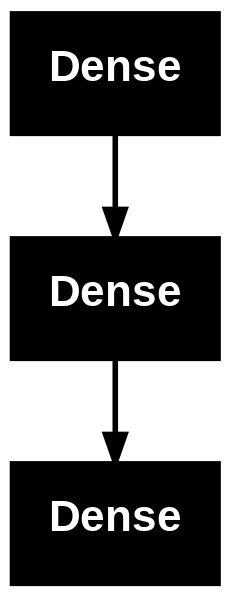

In [44]:
tf.keras.utils.plot_model(model_1)

### Compiling our MOdel with Hidden Layers

In [45]:
model_1.compile(optimizer = "adam",loss="binary_crossentropy",metrics = ['accuracy'])
model_1.fit(X_train,y_train,batch_size = 30, epochs = 20)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.4948 - loss: 1.0759
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6258 - loss: 0.6815 
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8583 - loss: 0.4544 
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9368 - loss: 0.3217 
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9562 - loss: 0.2505 
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9646 - loss: 0.1957 
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9642 - loss: 0.1666 
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9735 - loss: 0.1309 
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9766 - loss: 0.1198 
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9815 - loss: 0.0939 
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9779 - loss: 0.0879 
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 

### Model Evaluation of our model with Hidden Layers

In [48]:
X_test_new = pd.read_csv('https://raw.githubusercontent.com/dphi-official/Datasets/master/bank_note_data/testing_set_label.csv')

In [50]:
X_test_new.shape

(275, 4)

In [51]:
model_1.evaluate(X_test,y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 1.0000 - loss: 0.0152


[0.018117720261216164, 1.0]

We achieved 100% accuracy on our model

In [52]:
model_1.predict(X_test_new)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


array([[8.88769686e-01],
       [9.97929335e-01],
       [2.74598366e-04],
       [1.38132786e-03],
       [2.90624425e-03],
       [9.11830366e-01],
       [9.94231582e-01],
       [1.89692929e-01],
       [9.77940798e-01],
       [9.97971714e-01],
       [4.85901022e-03],
       [9.63162601e-01],
       [7.86838427e-05],
       [9.99522686e-01],
       [2.80390552e-04],
       [2.34747678e-03],
       [2.22654198e-04],
       [9.83887970e-01],
       [1.10890926e-03],
       [9.98918533e-01],
       [9.97296274e-01],
       [9.88056183e-01],
       [9.82726808e-04],
       [7.97114219e-04],
       [1.06344710e-03],
       [9.92819488e-01],
       [1.47694882e-04],
       [6.12274162e-04],
       [9.74521160e-01],
       [9.46573257e-01],
       [7.30079889e-01],
       [9.58003283e-01],
       [8.85696383e-04],
       [2.58591841e-03],
       [4.45646001e-03],
       [9.97902870e-01],
       [9.90545392e-01],
       [7.01196818e-03],
       [1.21396016e-02],
       [9.84334052e-01],
